METRICMIND — DATASET


,order_id,region,quarter,revenue,cost,profit,margin_pct
0,1001,Europe,Q1,12000,8000,4000,33.33
1,1002,Europe,Q1,15000,9000,6000,40.00
2,1003,Asia,Q1,10000,6500,3500,35.00
3,1004,North America,Q1,18000,12000,6000,33.33
4,1005,Europe,Q2,14000,10000,4000,28.57
5,1006,Asia,Q2,11000,7000,4000,36.36
6,1007,Europe,Q2,9000,7500,1500,16.67
7,1008,North America,Q2,20000,13000,7000,35.00
8,1009,Asia,Q3,13000,8000,5000,38.46
9,1010,Europe,Q3,10000,7500,2500,25.00



METRIC DEFINITIONS


,Metric,Definition
0,revenue,Sum of order revenue
1,cost,Sum of order cost
2,profit,Revenue minus cost
3,margin,Total profit / total revenue * 100



TEST QUESTION
MetricMind business analysis
Region: Europe
Quarter: Q2
Orders: 2
Revenue: 23,000.00
Cost: 17,500.00
Profit: 5,500.00
Profit margin: 23.91%
Metrics calculated using the approved definitions.


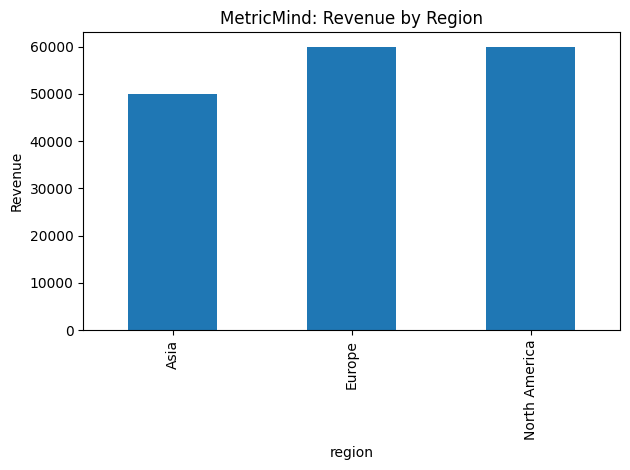


SUCCESS: Dataset, metric definitions, and chart created.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Sample business data
data = {
    "order_id": range(1001, 1013),
    "region": [
        "Europe", "Europe", "Asia", "North America",
        "Europe", "Asia", "Europe", "North America",
        "Asia", "Europe", "Asia", "North America"
    ],
    "quarter": ["Q1", "Q1", "Q1", "Q1", "Q2", "Q2",
                "Q2", "Q2", "Q3", "Q3", "Q3", "Q3"],
    "revenue": [12000,15000,10000,18000,14000,11000,
                9000,20000,13000,10000,16000,22000],
    "cost": [8000,9000,6500,12000,10000,7000,
             7500,13000,8000,7500,9500,14000]
}

df = pd.DataFrame(data)
df["profit"] = df["revenue"] - df["cost"]
df["margin_pct"] = (df["profit"] / df["revenue"] * 100).round(2)

# 2. Approved metric definitions
METRICS = {
    "revenue": "Sum of order revenue",
    "cost": "Sum of order cost",
    "profit": "Revenue minus cost",
    "margin": "Total profit / total revenue * 100"
}

def analyze(region=None, quarter=None):
    result = df.copy()

    if region:
        result = result[result["region"].str.lower() == region.lower()]

    if quarter:
        result = result[result["quarter"].str.upper() == quarter.upper()]

    if result.empty:
        return None

    revenue = result["revenue"].sum()
    cost = result["cost"].sum()
    profit = revenue - cost
    margin = profit / revenue * 100 if revenue else 0

    return {
        "Orders": len(result),
        "Revenue": revenue,
        "Cost": cost,
        "Profit": profit,
        "Profit margin (%)": round(margin, 2)
    }

# 3. Simple question interface
def metricmind(question):
    q = question.lower()
    region = next(
        (r for r in df["region"].unique() if r.lower() in q), None
    )
    quarter = next(
        (x for x in df["quarter"].unique() if x.lower() in q), None
    )

    if not any(word in q for word in
               ["revenue", "sales", "cost", "profit", "margin", "performance"]):
        return "Try asking about revenue, sales, cost, profit, or margin."

    result = analyze(region, quarter)

    if result is None:
        return "No matching records found."

    lines = [
        f"MetricMind business analysis",
        f"Region: {region or 'All regions'}",
        f"Quarter: {quarter or 'All quarters'}",
        f"Orders: {result['Orders']}",
        f"Revenue: {result['Revenue']:,.2f}",
        f"Cost: {result['Cost']:,.2f}",
        f"Profit: {result['Profit']:,.2f}",
        f"Profit margin: {result['Profit margin (%)']}%"
    ]

    if "margin" in q:
        lines.append("Definition: Total profit / total revenue × 100.")
    elif "profit" in q:
        lines.append("Definition: Total revenue minus total cost.")
    else:
        lines.append("Metrics calculated using the approved definitions.")

    return "\n".join(lines)

# 4. Verify results and show the dataset
print("METRICMIND — DATASET")
display(df)

print("\nMETRIC DEFINITIONS")
display(pd.DataFrame(
    list(METRICS.items()), columns=["Metric", "Definition"]
))

print("\nTEST QUESTION")
print(metricmind("Show European revenue in Q2"))

# 5. Create a regional revenue chart
regional = df.groupby("region")["revenue"].sum().sort_values()

regional.plot(kind="bar", title="MetricMind: Revenue by Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# 6. Save deliverables
df.to_csv("metricmind_sales.csv", index=False)

with open("metricmind_metrics.md", "w") as f:
    f.write("# MetricMind — Metric Definitions\n\n")
    for name, definition in METRICS.items():
        f.write(f"- **{name.title()}:** {definition}\n")

print("\nSUCCESS: Dataset, metric definitions, and chart created.")

In [4]:
metricmind("Show European revenue in Q2")

'MetricMind business analysis\nRegion: Europe\nQuarter: Q2\nOrders: 2\nRevenue: 23,000.00\nCost: 17,500.00\nProfit: 5,500.00\nProfit margin: 23.91%\nMetrics calculated using the approved definitions.'